In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix
)

In [2]:
df = pd.read_csv("SQLI_Dataset.csv")

print(df.head())
print(df.info())
print(df["label"].value_counts())

   no_letter  no_digit  no_special _char  no_keyword  length   entropy  \
0          0         8                 0           0       8  2.500000   
1          6         2                 0           0       8  2.750000   
2         23         4                 0           2      35  3.799874   
3          4         2                 0           0       6  2.251629   
4          1         8                 0           0       9  2.947703   

   no_semicolon  no_single_ qout  no_double_ qout  no_percentage  whit_ space  \
0             0                0                0              0            1   
1             0                0                0              0            1   
2             0                0                0              0            7   
3             0                0                0              0            1   
4             0                0                0              0            1   

   no_punctuation  no_logical _operat  no_operat  no_or  no_and  no_

In [3]:
df = df.dropna()
df = df.drop_duplicates()

X = df.drop("label", axis=1)
y = df["label"]

print("Features:", X.shape)
print("Labels:", y.shape)

Features: (33052, 18)
Labels: (33052,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 26441
Testing samples: 6611


In [5]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=8,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [6]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9860837997277265

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      2673
           1       1.00      0.98      0.99      3938

    accuracy                           0.99      6611
   macro avg       0.98      0.99      0.99      6611
weighted avg       0.99      0.99      0.99      6611



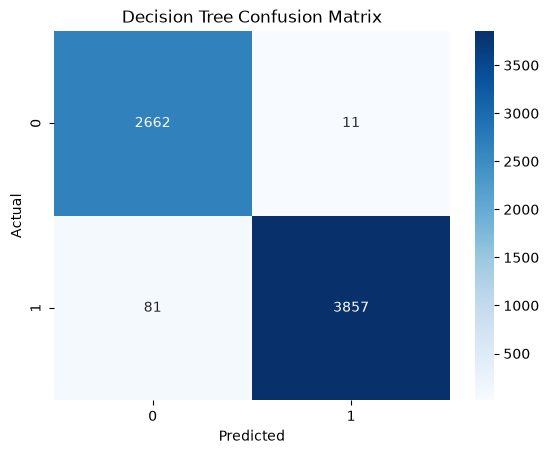

In [7]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

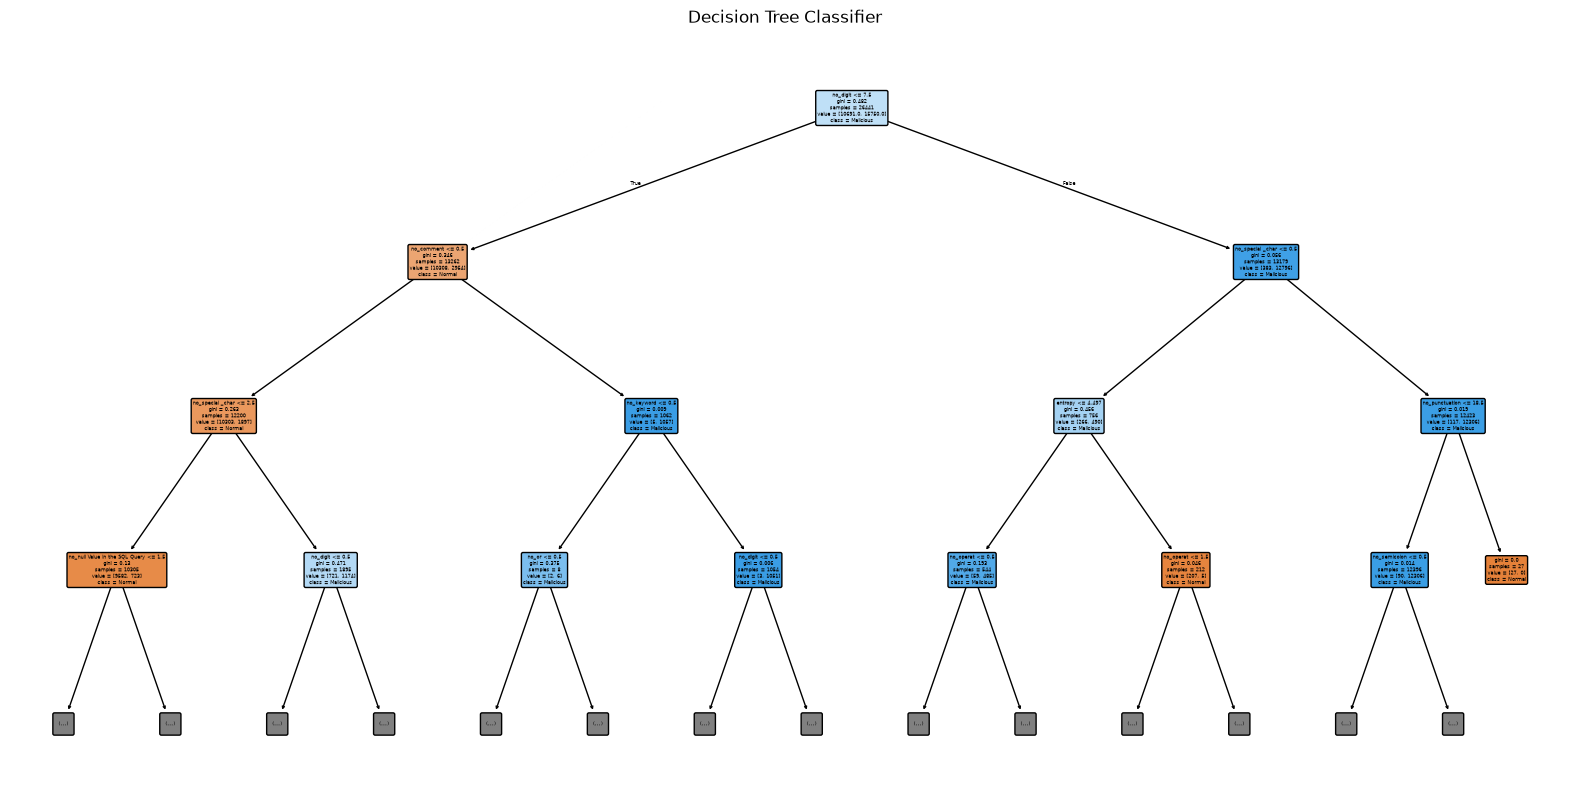

In [8]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Normal", "Malicious"],
    filled=True,
    rounded=True,
    max_depth=3
)

plt.title("Decision Tree Classifier")
plt.show()

In [9]:
def predict_injection(values):
    sample = pd.DataFrame([values], columns=X.columns)
    prediction = model.predict(sample)[0]

    if prediction == 1:
        print("Potentially Malicious SQL Injection")
    else:
        print("Normal Database Activity")